In [1]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit, log_expit, logsumexp
from scipy.stats import norm, t
import matplotlib.pyplot as plt

In [2]:
def lse2(a, b):
    """log(exp(a) + exp(b))"""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    m = np.maximum(a, b)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = m + np.log(np.exp(a - m) + np.exp(b - m))
    return np.where(np.isinf(m), m, out)

def lnorm(l, dx):
    """Normalise log-density on a uniform grid."""
    return l - np.log(np.sum(np.exp(l)) * dx)

def log_w(l, lref):
    """log[ e^l / (e^l + e^lref) ]"""
    with np.errstate(invalid="ignore"):
        x = np.asarray(l - lref, dtype=float)
    x = np.where(np.isnan(x), 0.0, x)  # both -Inf -> w = 0.5
    return log_expit(x)

def div_metrics(lp, lq, dx):
    """Inputs: normalised log-densities."""
    p = np.exp(lp)
    q = np.exp(lq)
    # Handle 0 * (-inf) safely where p or q underflows to 0
    kl = np.sum(np.where(p > 0, p * (lp - lq), 0.0)) * dx
    rkl = np.sum(np.where(q > 0, q * (lq - lp), 0.0)) * dx
    tv = 0.5 * np.sum(np.abs(p - q)) * dx
    return {"KL": kl, "RKL": rkl, "TV": tv}

In [3]:
def log_target(theta):
    theta = np.asarray(theta, dtype=float)
    l1 = (np.log(0.8) + np.log(2) + 
          t.logpdf(theta + 5, df=3) + 
          t.logcdf(-4 * (theta + 5), df=3))
    l2 = (np.log(0.2) + np.log(2) + 
          t.logpdf(theta - 5, df=3) + 
          t.logcdf(5 * (theta - 5), df=3))
    return lse2(l1, l2)

def nlt(th):
    return float(-log_target(np.asarray(th).item()))

def exact_nlt_derivs(theta, nu=3.0):
    def comp_derivs(x, alpha, log_w):
        # Log-density value
        l = log_w + np.log(2.0) + t.logpdf(x, df=nu) + t.logcdf(alpha * x, df=nu)
        
        # 1st and 2nd derivatives of log(t_pdf)
        d1_lpdf = -(nu + 1.0) * x / (nu + x**2)
        d2_lpdf = -(nu + 1.0) * (nu - x**2) / (nu + x**2)**2
        
        # 1st and 2nd derivatives of log(t_cdf(alpha * x))
        z = alpha * x
        r = np.exp(t.logpdf(z, df=nu) - t.logcdf(z, df=nu))
        d1_lpdf_z = -(nu + 1.0) * z / (nu + z**2)
        
        d1_lcdf = alpha * r
        d2_lcdf = (alpha**2) * r * (d1_lpdf_z - r)
        
        return l, d1_lpdf + d1_lcdf, d2_lpdf + d2_lcdf

    l1, d1_1, d2_1 = comp_derivs(theta + 5.0, -4.0, np.log(0.8))
    l2, d1_2, d2_2 = comp_derivs(theta - 5.0,  5.0, np.log(0.2))

    w1 = expit(l1 - l2)
    w2 = 1.0 - w1

    # Negate to get derivatives of nlt(theta) = -log_target(theta)
    grad = -(w1 * d1_1 + w2 * d1_2)
    hess = -(w1 * d2_1 + w2 * d2_2 + w1 * w2 * (d1_1 - d1_2)**2)
    return grad, hess

In [4]:
def fit_student_t_laplace(log_target, grad_nlt, hess_nlt, init_points, nu=3.0):
    mus, Hs = [], []
    for x0 in init_points:
        res = minimize(
            lambda th: float(-np.squeeze(log_target(float(th[0])))),
            x0=np.array([float(x0)]),
            method="BFGS",
            jac=lambda th: np.array([float(np.squeeze(grad_nlt(float(th[0]))))]),
            options={"gtol": 1e-10}
        )
        mu_k = float(res.x[0])
        g_k = float(np.squeeze(grad_nlt(mu_k)))
        H_k = float(np.squeeze(hess_nlt(mu_k)))

        assert abs(g_k) < 1e-7, f"Optimization failed from x0={x0}: grad={g_k}, msg={res.message}"
        assert H_k > 0, f"Non-positive Hessian at mu={mu_k}: H={H_k}"

        mus.append(mu_k)
        Hs.append(H_k)

    mu = np.array(mus)
    H = np.array(Hs)
    assert len(mu) < 2 or mu[0] < mu[1], f"Modes collapsed to the same point: {mu}"

    sdv = 1.0 / np.sqrt(H)
    scale_t = sdv * np.sqrt((nu + 1.0) / nu)

    logZ = np.array([float(np.squeeze(log_target(m))) for m in mu]) + 0.5 * np.log(2.0 * np.pi / H)
    lam = np.exp(logZ - logsumexp(logZ))

    def log_q_student_laplace(theta):
        theta = np.asarray(theta, dtype=float)
        comps = [
            np.log(lam[k]) + t.logpdf((theta - mu[k]) / scale_t[k], df=nu) - np.log(scale_t[k])
            for k in range(len(mu))
        ]
        return logsumexp(comps, axis=0)

    def log_r(theta, k):
        comps = [np.log(lam[j]) + norm.logpdf(theta, loc=mu[j], scale=sdv[j]) for j in range(len(mu))]
        return comps[k] - logsumexp(comps, axis=0)

    def log_q_skew_student_laplace(theta):
        theta = np.asarray(theta, dtype=float)
        comps = []
        for k in range(len(mu)):
            refl = 2.0 * mu[k] - theta
            l = log_target(theta) + log_r(theta, k)
            lr = log_target(refl) + log_r(refl, k)
            log_bk = t.logpdf((theta - mu[k]) / scale_t[k], df=nu) - np.log(scale_t[k])
            comps.append(np.log(lam[k]) + np.log(2.0) + log_bk + log_expit(l - lr))
        return logsumexp(comps, axis=0)

    return {
        "mu": mu,
        "H": H,
        "scale_t": scale_t,
        "lam": lam,
        "log_q_base": log_q_student_laplace,
        "log_q_skew": log_q_skew_student_laplace,
    }

In [5]:
def make_models(base="gauss", nu=3):
    if base == "t":
        fit = fit_student_t_laplace(
            log_target=log_target,
            grad_nlt=lambda th: exact_nlt_derivs(th)[0],
            hess_nlt=lambda th: exact_nlt_derivs(th)[1],
            init_points=[-10.0, 20.0],  # <-- Use 20.0 (or 5.0), NOT 10.0
            nu=nu
        )
        lb_mix = fit["log_q_base"]
        c_laplace = fit["log_q_skew"]
        lbk = lambda th, k: t.logpdf((th - mu[k]) / fit["scale_t"][k], df=nu) - np.log(fit["scale_t"][k])
    else:
        lbk = lambda th, k: norm.logpdf(th, loc=mu[k], scale=sdv[k])
        lb_mix = lambda th: lse2(np.log(lam[0]) + lbk(th, 0), np.log(lam[1]) + lbk(th, 1))
        logr_local = lambda th, k: (np.log(lam[k]) + lbk(th, k)) - lb_mix(th)
        local_comp = lambda th, k: (
            np.log(2) + lbk(th, k) +
            log_w(log_target(th) + logr_local(th, k), log_target(2 * mu[k] - th) + logr_local(2 * mu[k] - th, k))
        )
        c_laplace = lambda th: lse2(np.log(lam[0]) + local_comp(th, 0), np.log(lam[1]) + local_comp(th, 1))

    ts = np.mean(mu)
    lbar_B = lambda th: np.log(0.5) + lse2(lb_mix(th), lb_mix(2 * ts - th))
    loc = lambda th, k: log_target(th) + (
        (np.log(lam[k]) + norm.logpdf(th, loc=mu[k], scale=sdv[k])) -
        lse2(np.log(lam[0]) + norm.logpdf(th, loc=mu[0], scale=sdv[0]),
             np.log(lam[1]) + norm.logpdf(th, loc=mu[1], scale=sdv[1]))
    )

    models = {
        "Base": lb_mix,
        "B_global": lambda th: np.log(2) + lbar_B(th) + log_w(log_target(th), log_target(2 * ts - th)),
        "C_laplaceW": c_laplace,
    }
    return {"models": models, "lbk": lbk, "lbar_B": lbar_B, "loc": loc, "ts": ts}

In [6]:
def evaluate(base, nu=3, L=60.0, dx=0.005):
    g = np.arange(-L, L + 1e-12, dx)
    mod = make_models(base, nu)["models"]
    lp = lnorm(log_target(g), dx)
    rows = {}
    for name, f in mod.items():
        lq = f(g)
        metrics = div_metrics(lp, lnorm(lq, dx), dx)
        rows[name] = {"mass": np.sum(np.exp(lq)) * dx, **metrics}
    return pd.DataFrame.from_dict(rows, orient="index")

In [7]:
fit_t = fit_student_t_laplace(
    log_target=log_target,
    grad_nlt=lambda th: exact_nlt_derivs(th)[0],
    hess_nlt=lambda th: exact_nlt_derivs(th)[1],
    init_points=[-10.0, 20.0],  # <-- Use 20.0 (or 5.0), NOT 10.0
    nu=3.0
)

mu = fit_t["mu"]
H = fit_t["H"]
lam = fit_t["lam"]
sdv = 1.0 / np.sqrt(H)
print("Modes:", mu)
print("Weights:", lam)

Modes: [-5.3920896   5.36099503]
Weights: [0.8011656 0.1988344]


In [8]:
# Verify the theoretical identity of skew-symmetric approximations
# Want: D[pi||q_skew] == D[pibar||qbar] and D[pi||q_skew] < D[pi||qbar]
def check_identity(center, lpi_fun, lqbar_fun, label, L=60.0, dx=0.005):
    g = center + np.arange(-L, L + 1e-12, dx)
    lpi = lnorm(lpi_fun(g), dx)
    lqb = lnorm(lqbar_fun(g), dx)
    lq = np.log(2) + lqb + log_w(lpi, lpi[::-1])
    lpib = lse2(lpi, lpi[::-1]) - np.log(2)

    res = pd.DataFrame.from_dict({
        "D[pi||q_skew]":  div_metrics(lpi,  lq,  dx),
        "D[pibar||qbar]": div_metrics(lpib, lqb, dx),
        "D[pi||qbar]":    div_metrics(lpi,  lqb, dx),
    }, orient="index")
    print(f"\n-- {label} --")
    print(res.round(5))

for b in ["gauss", "t"]:
    M = make_models(b, 3)
    check_identity(M["ts"], log_target, M["lbar_B"], f"B_global, {b}")
    for k in range(2):
        check_identity(
            mu[k],
            lambda g, k=k, M=M: M["loc"](g, k),
            lambda g, k=k, M=M: M["lbk"](g, k),
            f"C component {k+1}, {b}"
        )


-- B_global, gauss --
                     KL      RKL       TV
D[pi||q_skew]   3.06093  0.31216  0.27317
D[pibar||qbar]  3.06093  0.31216  0.27317
D[pi||qbar]     3.25468  0.56113  0.37883

-- C component 1, gauss --
                     KL      RKL       TV
D[pi||q_skew]   2.83973  0.19565  0.21226
D[pibar||qbar]  2.83973  0.19565  0.21226
D[pi||qbar]     3.03785  0.30012  0.26804

-- C component 2, gauss --
                     KL      RKL       TV
D[pi||q_skew]   3.26155  0.22020  0.23149
D[pibar||qbar]  3.26155  0.22020  0.23149
D[pi||qbar]     3.49945  0.37366  0.29408

-- B_global, t --
                     KL      RKL       TV
D[pi||q_skew]   0.23963  0.35256  0.21249
D[pibar||qbar]  0.23963  0.35256  0.21249
D[pi||qbar]     0.43338  0.61761  0.37914

-- C component 1, t --
                     KL      RKL       TV
D[pi||q_skew]   0.03270  0.02611  0.07242
D[pibar||qbar]  0.03270  0.02611  0.07242
D[pi||qbar]     0.23083  0.48387  0.20732

-- C component 2, t --
              

In [9]:
def run_multimodal_sensitivity(nus=(1, 2, 3, 5, 10, 30), Ls=(30.0, 60.0, 120.0), dx=0.005):
    records = []
    # 1. Degrees-of-freedom sweep at fixed L=60
    for nu in nus:
        df_res = evaluate("t", nu=nu, L=60.0, dx=dx)
        for model_name in ["Base", "B_global", "C_laplaceW"]:
            records.append({
                "base": f"t (nu={nu})",
                "nu": nu,
                "L": 60.0,
                "model": model_name,
                "KL": df_res.loc[model_name, "KL"],
                "RKL": df_res.loc[model_name, "RKL"],
                "TV": df_res.loc[model_name, "TV"],
            })

    # 2. Grid-range sensitivity (Gauss vs. Student-t nu=3)
    grid_records = []
    for base in ["gauss", "t"]:
        for L in Ls:
            df_res = evaluate(base, nu=3, L=L, dx=dx)
            for model_name in ["Base", "B_global", "C_laplaceW"]:
                grid_records.append({
                    "base": base,
                    "L": L,
                    "model": model_name,
                    "KL": df_res.loc[model_name, "KL"],
                    "RKL": df_res.loc[model_name, "RKL"],
                    "TV": df_res.loc[model_name, "TV"],
                })

    df_nu = pd.DataFrame(records)
    df_L = pd.DataFrame(grid_records)

    print("===== 1. Degrees of Freedom (nu) Sensitivity (L = 60) =====")
    print(df_nu.pivot(index="nu", columns="model", values=["KL", "RKL", "TV"]).round(5))

    print("\n===== 2. Grid Truncation (L) Sensitivity =====")
    print(df_L.pivot(index=["base", "L"], columns="model", values=["KL", "RKL", "TV"]).round(5))

    return df_nu, df_L

df_nu, df_L = run_multimodal_sensitivity()

===== 1. Degrees of Freedom (nu) Sensitivity (L = 60) =====
            KL                          RKL                           TV  \
model B_global     Base C_laplaceW B_global     Base C_laplaceW B_global   
nu                                                                         
1      0.27499  0.27645    0.08269  0.82662  0.84431    0.15742  0.28144   
2      0.20745  0.20858    0.00544  0.45230  0.45956    0.00571  0.21589   
3      0.23963  0.24088    0.03569  0.35256  0.35771    0.02835  0.21249   
5      0.35092  0.35250    0.14658  0.30538  0.30939    0.07909  0.23058   
10     0.60298  0.60550    0.39944  0.29712  0.30041    0.13397  0.24974   
30     1.14200  1.14837    0.94229  0.30472  0.30753    0.17722  0.26485   

                           
model     Base C_laplaceW  
nu                         
1      0.28188    0.13230  
2      0.21598    0.04201  
3      0.21250    0.07617  
5      0.23062    0.12880  
10     0.24980    0.17118  
30     0.26492    0.20085  

==

In [10]:
# Visualization for one simulation
def plot_model_densities(base="t", nu=3, xlim=(-15, 15), dx=0.005):
    g = np.arange(xlim[0], xlim[1] + 1e-12, dx)
    M = make_models(base=base, nu=nu)
    models = M["models"]
    pi_vals = np.exp(log_target(g))

    qbar_funs = {
        "Base":       models["Base"],
        "B_global":   M["lbar_B"],
        "C_laplaceW": models["Base"],
    }
    titles = {
        "Base":       "Base (Symmetric Mixture)",
        "B_global":   "Global Reflection at $t_s$",
        "C_laplaceW": "Localized Partition",
    }

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

    for ax, name in zip(axes, ["Base", "B_global", "C_laplaceW"]):
        q_vals = np.exp(models[name](g))
        qbar_vals = np.exp(qbar_funs[name](g))

        ax.plot(g, pi_vals, color="black", lw=2.2, label=r"True $\pi(\theta)$")
        if name == "Base":
            ax.plot(g, qbar_vals, color="#1f77b4", ls="--", lw=1.8,
                    label=r"$\bar{q}(\theta) = q(\theta)$")
        else:
            ax.plot(g, qbar_vals, color="#7f7f7f", ls="--", lw=1.6,
                    label=r"Symmetric $\bar{q}(\theta)$")
            ax.plot(g, q_vals, color="#d62728", lw=2.0,
                    label=r"Skewed $q(\theta)$")

        for k in range(2):
            ax.axvline(mu[k], color="gray", ls=":", lw=1.0, alpha=0.7)
        if name == "B_global":
            ax.axvline(M["ts"], color="#2ca02c", ls="-.", lw=1.2, alpha=0.8,
                       label=r"Midpoint $t_s$")

        ax.set_title(titles[name], fontsize=11, fontweight="bold")
        ax.set_xlabel(r"$\theta$", fontsize=11)
        ax.grid(True, alpha=0.25)
        ax.legend(loc="upper right", fontsize=8.5, frameon=True)

    axes[0].set_ylabel("Density", fontsize=11)
    base_label = "Gaussian Base" if base == "gauss" else rf"Student-$t$ Base ($\nu = {nu}$)"
    fig.suptitle(rf"Target $\pi(\theta)$, Base $\bar{{q}}(\theta)$, and Approximation $q(\theta)$ — {base_label}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

===== Results: Student-t Laplace (nu = 3) =====
                mass        KL       RKL        TV
Base        0.999998  0.240882  0.357705  0.212496
B_global    0.999998  0.239633  0.352565  0.212487
C_laplaceW  0.999997  0.035685  0.028355  0.076166

-- C component 1, Student-t (nu=3) --
                     KL      RKL       TV
D[pi||q_skew]   0.03270  0.02611  0.07242
D[pibar||qbar]  0.03270  0.02611  0.07242
D[pi||qbar]     0.23083  0.48387  0.20732

-- C component 2, Student-t (nu=3) --
                    KL      RKL       TV
D[pi||q_skew]   0.0476  0.03738  0.09109
D[pibar||qbar]  0.0476  0.03738  0.09109
D[pi||qbar]     0.2855  0.58641  0.23408


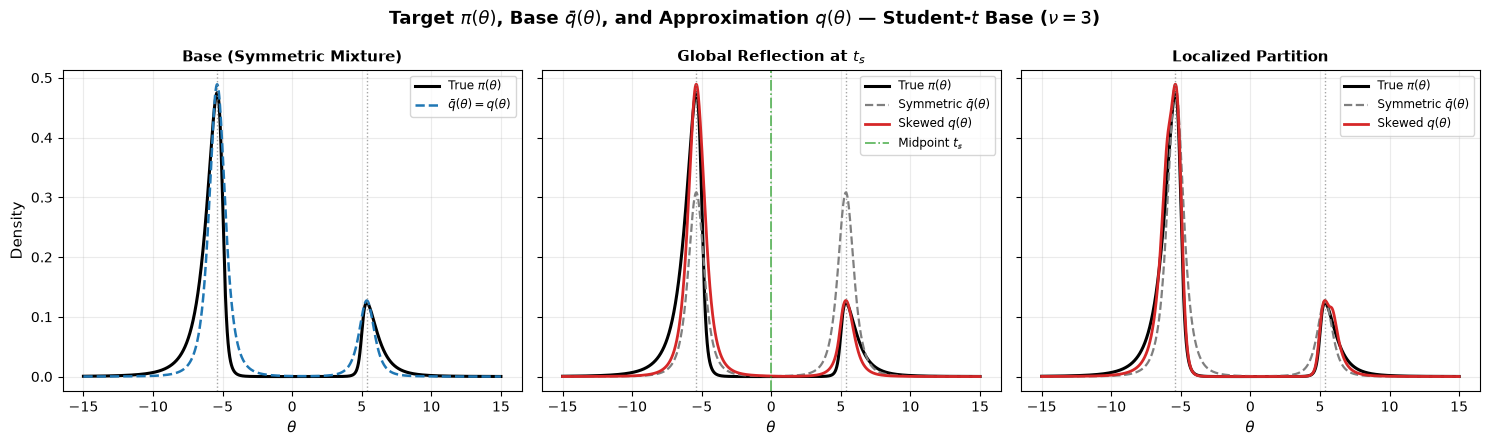

In [11]:
# 1. Evaluate divergence metrics (just like evaluate("gauss"))
print("===== Results: Student-t Laplace (nu = 3) =====")
print(evaluate(base="t", nu=3))

# 2. Get the log-density functions directly (just like make_models("gauss"))
M_t = make_models(base="t", nu=3)
models_t = M_t["models"]

# Evaluate at any grid or array of theta values:
theta_grid = np.linspace(-15, 15, 1000)
log_q_base = models_t["Base"](theta_grid)             # Symmetric Student-t Laplace
log_q_global = models_t["B_global"](theta_grid)       # Global Skew-Student-t Laplace
log_q_local = models_t["C_laplaceW"](theta_grid)      # Local Skew-Student-t Laplace

# 3. Run the unit tests (check_identity) for Student-t Laplace
for k in range(2):
    check_identity(
        mu[k],
        lambda g, k=k, M=M_t: M["loc"](g, k),
        lambda g, k=k, M=M_t: M["lbk"](g, k),
        f"C component {k+1}, Student-t (nu=3)"
    )

# 4. Plot the densities (just like plot_model_densities(base="gauss"))
plot_model_densities(base="t", nu=3, xlim=(-15, 15))